# Dự đoán ung thư phổi bằng hồi quy Logistic

*Bài 4, mục 4.3.3 – 4.3.4.* Tiền xử lý giống notebook 09, sau đó xây dựng và đánh giá mô hình.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

DATA = Path('..') / 'data'
df = pd.read_csv(DATA / 'survey lung cancer.csv')
df.columns = df.columns.str.strip()
df = df.drop_duplicates()
df['GENDER'] = (df['GENDER'] == 'M').astype(int)
df['LUNG_CANCER'] = (df['LUNG_CANCER'] == 'YES').astype(int)
symptoms = df.columns.drop(['GENDER', 'AGE', 'LUNG_CANCER'])
df[symptoms] = df[symptoms] - 1

X = df.drop(columns='LUNG_CANCER')
y = df['LUNG_CANCER']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

## 1. Xây dựng mô hình (4.3.3)

`Pipeline` ghép chuẩn hóa và mô hình: `StandardScaler` chỉ học trung bình, độ lệch chuẩn trên tập huấn luyện.

In [2]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

logistic_model = model[-1]
print('w0 =', logistic_model.intercept_)
pd.Series(logistic_model.coef_[0], index=X.columns).sort_values(ascending=False).round(3)

w0 = [3.77649357]


CHRONIC DISEASE          1.363
FATIGUE                  1.094
ALLERGY                  0.785
PEER_PRESSURE            0.746
SWALLOWING DIFFICULTY    0.740
COUGHING                 0.736
ALCOHOL CONSUMING        0.717
YELLOW_FINGERS           0.562
WHEEZING                 0.482
SMOKING                  0.464
ANXIETY                  0.423
CHEST PAIN               0.302
GENDER                   0.000
AGE                     -0.043
SHORTNESS OF BREATH     -0.093
dtype: float64

## 2. Chốt ngưỡng trên tập huấn luyện (4.3.4 c)

Trước khi xem kết quả test, quy định **Recall OOF ≥ 0.95**, rồi chọn ngưỡng có độ đặc hiệu lớn nhất trong các ngưỡng đạt yêu cầu. Đây là tiêu chí giả định minh họa cách chọn ngưỡng, không phải khuyến nghị y khoa. Mỗi dự đoán train đến từ mô hình không học mẫu đó (`cross_val_predict`); scaler chỉ fit trên phần train của từng fold. Ngưỡng 0 bảo đảm có ứng viên đạt Recall mục tiêu.


In [3]:
# Chọn ngưỡng chỉ từ dự đoán ngoài fold của tập huấn luyện
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_prob = cross_val_predict(model, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
recall_target = 0.95       # chỉ tiêu giả định cho bài tập, không phải ngưỡng y khoa
threshold_rows = []
for tau in [0.0, 0.3, 0.5, 0.7, 0.8, 0.9]:
    tn, fp, fn, tp = confusion_matrix(y_train, oof_prob >= tau, labels=[0, 1]).ravel()
    threshold_rows.append({'threshold': tau, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                           'recall': tp / (tp + fn), 'specificity': tn / (tn + fp)})
threshold_table = pd.DataFrame(threshold_rows)
eligible = threshold_table[threshold_table['recall'] >= recall_target]
# Trong các ngưỡng đạt Recall mục tiêu, ưu tiên độ đặc hiệu lớn nhất
selected = eligible.sort_values(['specificity', 'recall', 'threshold'],
                                 ascending=[False, False, True]).iloc[0]
best_threshold = float(selected['threshold'])
print(threshold_table.round(3).to_string(index=False))
print('Ngưỡng chốt từ OOF train:', best_threshold)


 threshold  TN  FP  FN  TP  recall  specificity
       0.0   0  30   0 190   1.000        0.000
       0.3  10  20   3 187   0.984        0.333
       0.5  17  13   6 184   0.968        0.567
       0.7  20  10   8 182   0.958        0.667
       0.8  21   9  23 167   0.879        0.700
       0.9  24   6  35 155   0.816        0.800
Ngưỡng chốt từ OOF train: 0.7


## 3. Ma trận nhầm lẫn và các chỉ số (4.3.4 a)

In [4]:
y_pred = model.predict(X_test)                # mô hình mốc cố định, ngưỡng 0.5
y_prob = model.predict_proba(X_test)[:, 1]    # điểm số lớp dương cho ROC-AUC
print(confusion_matrix(y_test, y_pred))
print('Accuracy :', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall   :', recall_score(y_test, y_pred))
print('F1       :', f1_score(y_test, y_pred))
print('ROC-AUC  :', roc_auc_score(y_test, y_prob))
print(classification_report(y_test, y_pred, digits=3))

[[ 4  4]
 [ 2 46]]
Accuracy : 0.8928571428571429
Precision: 0.92
Recall   : 0.9583333333333334
F1       : 0.9387755102040817
ROC-AUC  : 0.9427083333333334
              precision    recall  f1-score   support

           0      0.667     0.500     0.571         8
           1      0.920     0.958     0.939        48

    accuracy                          0.893        56
   macro avg      0.793     0.729     0.755        56
weighted avg      0.884     0.893     0.886        56



So sánh với mô hình "ngây thơ" luôn dự đoán "có bệnh": Accuracy và F1 của nó cũng rất cao vì dữ liệu mất cân bằng.

In [5]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
y_dummy = dummy.predict(X_test)
print('Luôn dự đoán có bệnh: Accuracy = %.3f, F1 = %.3f'
      % (accuracy_score(y_test, y_dummy), f1_score(y_test, y_dummy)))

Luôn dự đoán có bệnh: Accuracy = 0.857, F1 = 0.923


## 4. So sánh cấu hình cố định: `class_weight='balanced'` (4.3.4 b)

Hai cấu hình được định trước để minh họa đánh đổi FP/FN. Không dùng bảng test để chọn cấu hình tốt nhất.

In [6]:
model_balanced = make_pipeline(StandardScaler(),
                         LogisticRegression(class_weight='balanced', max_iter=1000))
model_balanced.fit(X_train, y_train)
y_pred_balanced = model_balanced.predict(X_test)
print(confusion_matrix(y_test, y_pred_balanced))
print('Accuracy = %.3f, Precision = %.3f, Recall = %.3f, F1 = %.3f, ROC-AUC = %.3f' % (
    accuracy_score(y_test, y_pred_balanced), precision_score(y_test, y_pred_balanced),
    recall_score(y_test, y_pred_balanced), f1_score(y_test, y_pred_balanced),
    roc_auc_score(y_test, model_balanced.predict_proba(X_test)[:, 1])))

[[ 8  0]
 [ 6 42]]
Accuracy = 0.893, Precision = 1.000, Recall = 0.875, F1 = 0.933, ROC-AUC = 0.958


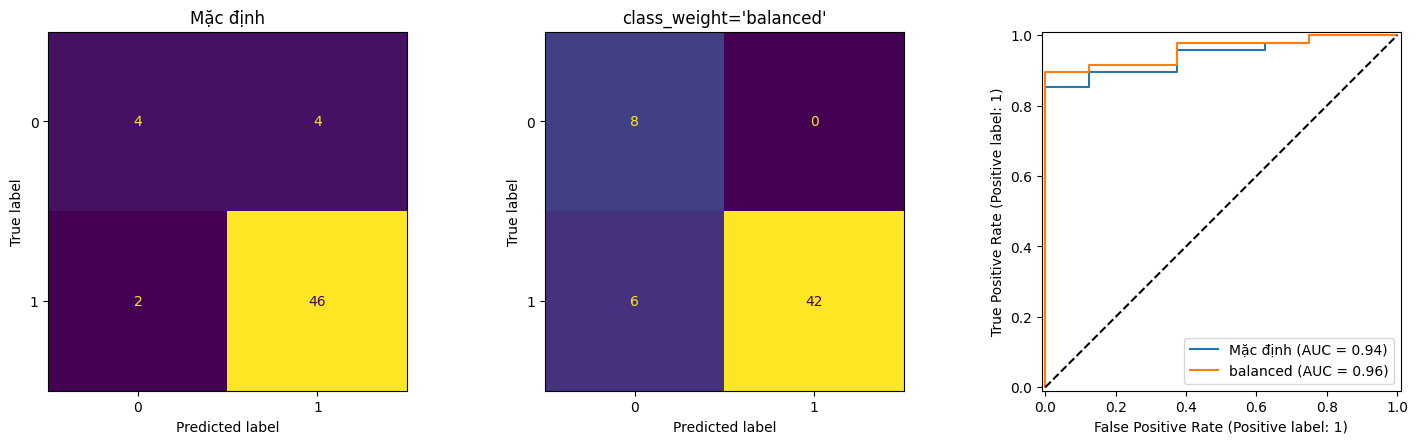

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, colorbar=False, ax=axes[0])
axes[0].set_title('Mặc định')
ConfusionMatrixDisplay.from_estimator(model_balanced, X_test, y_test, colorbar=False, ax=axes[1])
axes[1].set_title("class_weight='balanced'")
RocCurveDisplay.from_estimator(model, X_test, y_test, name='Mặc định', ax=axes[2])
RocCurveDisplay.from_estimator(model_balanced, X_test, y_test, name='balanced', ax=axes[2])
axes[2].plot([0, 1], [0, 1], 'k--')
plt.tight_layout()
plt.show()

## 5. Đánh giá ngưỡng đã chốt trên test (4.3.4 c)

Áp dụng đúng một ngưỡng đã chọn từ OOF train, không thử lại các ngưỡng theo kết quả test.

In [8]:
y_selected = (y_prob >= best_threshold).astype(int)
print('Ngưỡng đã chốt:', best_threshold)
print(confusion_matrix(y_test, y_selected, labels=[0, 1]))
print(classification_report(y_test, y_selected, digits=3, zero_division=0))


Ngưỡng đã chốt: 0.7
[[ 5  3]
 [ 3 45]]
              precision    recall  f1-score   support

           0      0.625     0.625     0.625         8
           1      0.938     0.938     0.938        48

    accuracy                          0.893        56
   macro avg      0.781     0.781     0.781        56
weighted avg      0.893     0.893     0.893        56



## 6. Kiểm định chéo trên tập huấn luyện (4.3.4 d)

Đánh giá thêm Logistic mặc định bằng CV trên train; giữ riêng test. Điểm CV dùng ngưỡng 0.5, không phải đánh giá không thiên lệch của quy trình chọn ngưỡng trên cùng các fold. Muốn đánh giá toàn bộ quy trình chọn ngưỡng bằng CV cần CV lồng nhau.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for metric in ['accuracy', 'f1', 'roc_auc']:
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring=metric)
    print(metric, scores.round(3), 'trung bình = %.3f' % scores.mean())

accuracy [0.886 0.909 0.955 0.864 0.955] trung bình = 0.914
f1 [0.935 0.947 0.974 0.925 0.974] trung bình = 0.951
roc_auc [0.899 0.912 0.969 0.877 0.947] trung bình = 0.921


## 7. So sánh với thuật toán PLA (Perceptron) (4.3.4 e)

Dùng cùng tập huấn luyện/kiểm tra và cùng bước chuẩn hóa, thay hồi quy Logistic bằng Perceptron để so sánh hai phương pháp.

### 7.1. PLA bằng NumPy: dữ liệu có tách biệt tuyến tính không?

Cài PLA theo mục 4.2.3: nhãn đổi sang $\{-1, +1\}$, thêm cột 1 vào $\mathbf{X}$, mỗi **epoch** duyệt lần lượt các mẫu train và cập nhật $\mathbf{w} \leftarrow \mathbf{w} + y_i\mathbf{x}_i$ khi mẫu $i$ bị phân loại sai. Sau mỗi epoch đếm số điểm sai trên toàn tập train. Nếu dữ liệu tách biệt tuyến tính, số điểm sai sẽ về 0 và PLA dừng.

PLA - số điểm sai qua các epoch: [32, 28, 26, 28, 22, 23, 21, 26, 26, 19, 26, 23, 23, 24, 20, 26, 27, 20, 18, 25, 27, 25, 23, 27, 22, 27, 15, 24, 28, 24, 21, 30, 17, 26, 28, 23, 14, 18, 20, 23, 18, 19, 30, 24, 26, 23, 14, 21, 25, 24]
PLA: nhỏ nhất = 14, lớn nhất = 32, epoch cuối = 24
Logistic: 15 điểm sai trên 220 mẫu train


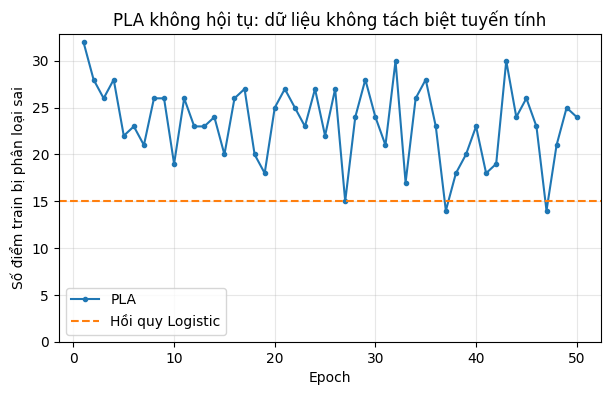

In [10]:
import matplotlib.pyplot as plt

scaler = StandardScaler().fit(X_train)                  # chuẩn hóa học trên train
X_train_bar = np.hstack([np.ones((len(X_train), 1)),    # thêm cột 1 cho hệ số chệch w0
                         scaler.transform(X_train)])
y_train_pm = np.where(y_train.to_numpy() == 1, 1, -1)   # nhãn PLA: +1 có bệnh, -1 không bệnh

n_epochs = 50                                  # số lần duyệt hết tập train
w = np.zeros(X_train_bar.shape[1])             # trọng số w = [w0, w1, ..., wd], khởi tạo 0
pla_errors = []                                # số điểm train bị sai sau mỗi epoch
for epoch in range(n_epochs):
    for i in range(len(y_train_pm)):
        if y_train_pm[i] * (X_train_bar[i] @ w) <= 0:   # điểm i bị phân loại sai
            w = w + y_train_pm[i] * X_train_bar[i]      # cập nhật w <- w + y_i x_i
    y_hat = np.where(X_train_bar @ w >= 0, 1, -1)
    pla_errors.append(int(np.sum(y_hat != y_train_pm)))

logistic_errors = int(np.sum(model.predict(X_train) != y_train))   # số điểm train sai của Logistic
print('PLA - số điểm sai qua các epoch:', pla_errors)
print('PLA: nhỏ nhất = %d, lớn nhất = %d, epoch cuối = %d' % (min(pla_errors), max(pla_errors), pla_errors[-1]))
print('Logistic: %d điểm sai trên %d mẫu train' % (logistic_errors, len(y_train)))

plt.figure(figsize=(7, 4))
plt.plot(range(1, n_epochs + 1), pla_errors, 'o-', ms=3, label='PLA')
plt.axhline(logistic_errors, color='tab:orange', ls='--', label='Hồi quy Logistic')
plt.xlabel('Epoch'); plt.ylabel('Số điểm train bị phân loại sai')
plt.title('PLA không hội tụ: dữ liệu không tách biệt tuyến tính')
plt.ylim(bottom=0); plt.grid(alpha=0.3); plt.legend(); plt.show()

Số điểm sai của PLA dao động mà không về 0: dữ liệu **không tách biệt tuyến tính**, PLA không bao giờ dừng, $\mathbf{w}$ cuối cùng phụ thuộc vào thời điểm cắt vòng lặp. Hồi quy Logistic tối ưu một hàm lồi nên cho nghiệm ổn định.

### 7.2. Perceptron của scikit-learn

`Perceptron` không có `predict_proba` vì chỉ cho nhãn cứng. Để vẽ ROC và tính ROC-AUC, dùng `decision_function`, trả về điểm số $s = \mathbf{x}^T\mathbf{w}$: điểm càng lớn càng nghiêng về lớp dương. `Perceptron` của scikit-learn tự dừng khi hàm mất mát không giảm thêm (`tol`), nên vẫn kết thúc dù dữ liệu không tách biệt tuyến tính.

In [11]:
from sklearn.linear_model import Perceptron

perceptron_model = make_pipeline(StandardScaler(), Perceptron(max_iter=1000, random_state=42))
perceptron_model.fit(X_train, y_train)
print('Số epoch đã chạy:', perceptron_model[-1].n_iter_)

y_pred_perceptron = perceptron_model.predict(X_test)
score_perceptron = perceptron_model.decision_function(X_test)   # điểm số s = x^T w, dùng cho ROC-AUC
print(confusion_matrix(y_test, y_pred_perceptron))

def evaluate(y_true, y_pred, score):
    """Các chỉ số đánh giá trên tập kiểm tra; score là xác suất hoặc điểm số của lớp dương."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
            'Accuracy': accuracy_score(y_true, y_pred), 'Precision': precision_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred), 'F1': f1_score(y_true, y_pred),
            'ROC-AUC': roc_auc_score(y_true, score)}

comparison = pd.DataFrame({
    'Logistic': evaluate(y_test, y_pred, y_prob),
    'Perceptron': evaluate(y_test, y_pred_perceptron, score_perceptron)}).T
comparison = comparison.astype({'TN': int, 'FP': int, 'FN': int, 'TP': int})
comparison.round(3)

Số epoch đã chạy: 9
[[ 5  3]
 [ 3 45]]


,TN,FP,FN,TP,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic,4,4,2,46,0.893,0.920,0.958,0.939,0.943
Perceptron,5,3,3,45,0.893,0.938,0.938,0.938,0.909


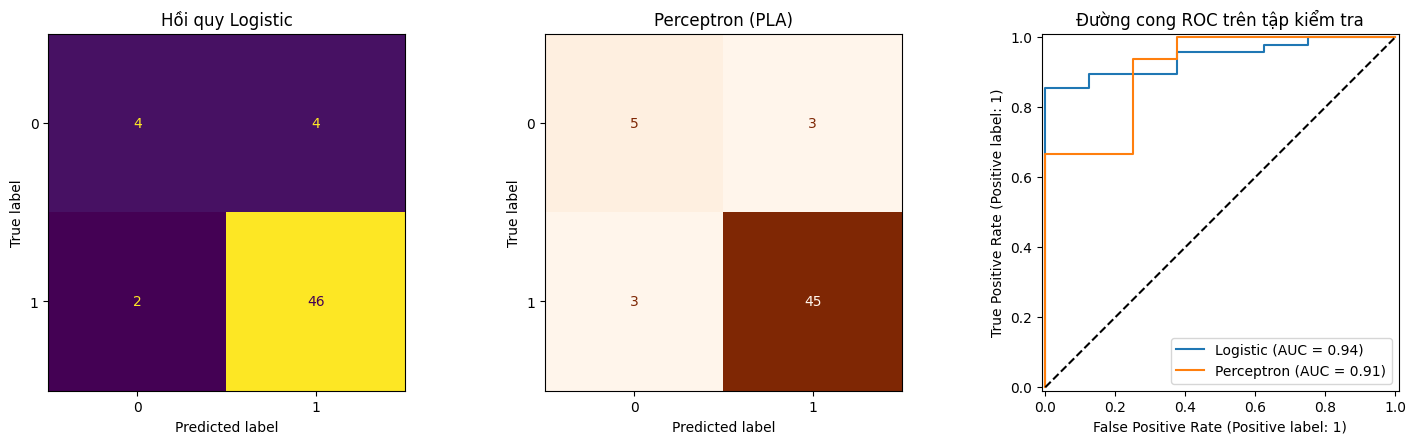

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, colorbar=False, ax=axes[0])
axes[0].set_title('Hồi quy Logistic')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_perceptron, cmap='Oranges', colorbar=False, ax=axes[1])
axes[1].set_title('Perceptron (PLA)')
RocCurveDisplay.from_predictions(y_test, y_prob, name='Logistic', ax=axes[2])
RocCurveDisplay.from_predictions(y_test, score_perceptron, name='Perceptron', ax=axes[2])
axes[2].plot([0, 1], [0, 1], 'k--')
axes[2].set_title('Đường cong ROC trên tập kiểm tra')
plt.tight_layout()
plt.show()

### 7.3. Độ ổn định: kiểm định chéo và thứ tự duyệt dữ liệu

Tập test nhỏ (8 mẫu lớp 0) nên chênh lệch một hai mẫu chưa đủ kết luận. So sánh thêm bằng CV 5 phần trên train (cùng các fold như mục 6). Nghiệm của PLA còn phụ thuộc thứ tự duyệt mẫu (`random_state` khi xáo trộn), nên lặp lại với 10 giá trị `random_state`.

In [13]:
from sklearn.model_selection import cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'f1', 'roc_auc']
cv_rows = []
for name, estimator in [('Logistic', model), ('Perceptron', perceptron_model)]:
    result = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring)
    for metric in scoring:
        scores = result['test_' + metric]
        cv_rows.append({'model': name, 'metric': metric, 'mean': scores.mean(), 'std': scores.std()})
cv_table = pd.DataFrame(cv_rows).pivot(index='model', columns='metric', values=['mean', 'std'])
print(cv_table.round(3))

# Perceptron với các thứ tự duyệt khác nhau: ROC-AUC trung bình CV trên train
seed_auc = [cross_val_score(make_pipeline(StandardScaler(), Perceptron(max_iter=1000, random_state=seed)),
                            X_train, y_train, cv=cv, scoring='roc_auc').mean() for seed in range(10)]
print('Perceptron, ROC-AUC CV theo random_state 0..9:', np.round(seed_auc, 3))
print('Khoảng dao động: %.3f - %.3f' % (min(seed_auc), max(seed_auc)))

               mean                     std              
metric     accuracy     f1 roc_auc accuracy    f1 roc_auc
model                                                    
Logistic      0.914  0.951   0.921    0.036  0.02   0.033
Perceptron    0.891  0.937   0.871    0.017  0.01   0.061


Perceptron, ROC-AUC CV theo random_state 0..9: [0.858 0.875 0.889 0.879 0.901 0.909 0.877 0.884 0.877 0.879]
Khoảng dao động: 0.858 - 0.909


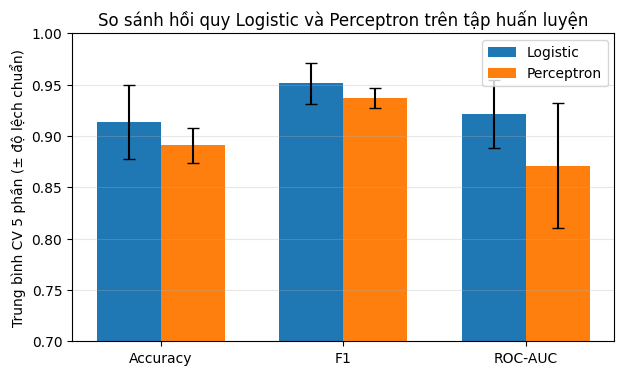

In [14]:
means = cv_table['mean'][scoring]
stds = cv_table['std'][scoring]
positions = np.arange(len(scoring))
plt.figure(figsize=(7, 4))
for k, name in enumerate(['Logistic', 'Perceptron']):
    plt.bar(positions + (k - 0.5) * 0.35, means.loc[name], width=0.35,
            yerr=stds.loc[name], capsize=4, label=name)
plt.xticks(positions, ['Accuracy', 'F1', 'ROC-AUC'])
plt.ylim(0.7, 1.0); plt.ylabel('Trung bình CV 5 phần (± độ lệch chuẩn)')
plt.title('So sánh hồi quy Logistic và Perceptron trên tập huấn luyện')
plt.grid(axis='y', alpha=0.3); plt.legend(); plt.show()

**Nhận xét.**

- Trên tập kiểm tra, hai mô hình có Accuracy bằng nhau, chỉ khác nhau một mẫu ở ma trận nhầm lẫn; nhưng ROC-AUC của Perceptron thấp hơn. Điểm số $\mathbf{x}^T\mathbf{w}$ của Perceptron không được huấn luyện để xếp hạng mọi mẫu, chỉ để đặt đúng phía siêu phẳng.
- Trên CV, Logistic tốt hơn ở cả ba chỉ số, ROC-AUC của Perceptron dao động mạnh hơn giữa các fold và giữa các thứ tự duyệt.
- Logistic cho **xác suất**, nên chọn được ngưỡng theo yêu cầu Recall (mục 2). Perceptron chỉ cho nhãn cứng; muốn đổi ngưỡng phải dùng điểm số $\mathbf{x}^T\mathbf{w}$, không có ý nghĩa xác suất.
- Với bài toán y khoa cần xác suất và cần chọn ngưỡng, hồi quy Logistic phù hợp hơn PLA.